Name: Mingze Geng

Usc ID: 1418612987

Github: Mingze888



## 1(a)–(b)(i)


In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from threadpoolctl import threadpool_limits

csv_path = Path("Frogs_MFCCs.csv")
if not csv_path.is_file():
    csv_path = Path("upload") / "Frogs_MFCCs.csv"
df = pd.read_csv(csv_path)
targets = ["Family", "Genus", "Species"]
X = df.filter(regex=r"^MFCC").to_numpy()
y = df[targets]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.70, random_state=42
)
print(f"{len(X):,} rows, {X.shape[1]} features, "
      f"{len(X_train):,} train and {len(X_test):,} test")
print(y.nunique().to_string())

def hamming_metrics(actual, predicted):
    wrong = np.asarray(actual) != np.asarray(predicted)
    distance = wrong.sum(axis=1)
    return {
        "Exact match": (distance == 0).mean(),
        "Hamming distance": distance.mean(),
        "Hamming score": 1 - wrong.mean(),
        "Hamming loss": wrong.mean(),
    }


7,195 rows, 22 features, 5,036 train and 2,159 test
Family      4
Genus       8
Species    10


Exact match is the fraction of rows where all three labels (Family, Genus, and Species) are correct.

Hamming loss is the fraction of individual label fields that are incorrect.

Hamming score  is 1 - Hamming loss. Mean Hamming distance  is the average number of incorrect label fields per row.

## 1(b)(ii)–(iv)


In [22]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rbf_grid = {
    "estimator__C": [0.1, 1, 10, 100, 1000],
    "estimator__gamma": [0.1, 0.5, 1, 2, 5, 10],
}
linear_grid = {
    "onevsrestclassifier__estimator__C": np.logspace(-3, 2, 6)
}


def linear_model(weight=None):
    return make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                loss="squared_hinge",
                dual=False,
                class_weight=weight,
                random_state=42,
                max_iter=300000,
                tol=1e-3,
            )
        ),
    )


models = {
    "Gaussian SVM": (OneVsRestClassifier(SVC(kernel="rbf")), rbf_grid),
    "L1 linear SVM": (linear_model(), linear_grid),
    "Balanced L1 linear SVM": (linear_model("balanced"), linear_grid),
}

details = []
results = []

for name, (model, grid) in models.items():
    predictions = {}

    for label in targets:
        search = GridSearchCV(
            model, grid, cv=cv, scoring="accuracy", n_jobs=6, error_score="raise"
        )
        search.fit(X_train, y_train[label])
        pred = search.predict(X_test)
        predictions[label] = pred

        params = {
            key.split("__")[-1]: value
            for key, value in search.best_params_.items()
        }
        gamma = params.get("gamma", np.nan)

        details.append({
            "Model": name,
            "Label": label,
            "C": params["C"],
            "gamma": gamma,
            "sigma": (2 * gamma) ** -0.5,
            "CV accuracy": search.best_score_,
            "Test accuracy": (pred == y_test[label]).mean(),
            "Macro recall": recall_score(y_test[label], pred, average="macro"),
        })

    results.append({
        "Model": name,
        **hamming_metrics(y_test, pd.DataFrame(predictions)[targets]),
    })

print(pd.DataFrame(details).round(4).to_string(index=False, na_rep="—"))
print()
print(pd.DataFrame(results).round(4).to_string(index=False))

                 Model   Label     C  gamma  sigma  CV accuracy  Test accuracy  Macro recall
          Gaussian SVM  Family 100.0    2.0    0.5       0.9927         0.9954        0.9782
          Gaussian SVM   Genus  10.0    2.0    0.5       0.9915         0.9907        0.9599
          Gaussian SVM Species 100.0    2.0    0.5       0.9911         0.9912        0.9693
         L1 linear SVM  Family 100.0      —      —       0.9408         0.9282        0.6902
         L1 linear SVM   Genus 100.0      —      —       0.9517         0.9416        0.7734
         L1 linear SVM Species  10.0      —      —       0.9607         0.9588        0.8945
Balanced L1 linear SVM  Family 100.0      —      —       0.9319         0.9208        0.9064
Balanced L1 linear SVM   Genus   1.0      —      —       0.9361         0.9310        0.8941
Balanced L1 linear SVM Species   1.0      —      —       0.9563         0.9565        0.9118

                 Model  Exact match  Hamming distance  Hamming score 

The Gaussian SVM performed best, with 98.89% exact match and 0.76% Hamming loss. The unweighted L1 SVM achieved 91.25% exact match, and the class-weighted L1 SVM achieved 89.58%. Class weighting improved macro recall for all three labels, including Family (69.02% to 90.64%), Genus (77.34% to 89.41%), and Species (89.45% to 91.18%). 



## 2(a)–(c)


In [25]:
def cluster_trial(seed):
    best_score = -np.inf
    with threadpool_limits(limits=1):
        for k in range(1, 51):
            clusters = KMeans(n_clusters=k, n_init=1, random_state=seed).fit_predict(X)
            if k == 1:  # CH is undefined for a single cluster.
                continue
            score = calinski_harabasz_score(X, clusters)
            if score > best_score:
                best_score, best_k, best_clusters = score, k, clusters

    majority = y.groupby(best_clusters).agg(lambda column: column.mode().iloc[0])
    predicted = majority.loc[best_clusters, targets]
    return {"Seed": seed, "k": best_k, "CH": best_score,
            **hamming_metrics(y, predicted)}, majority

trials = Parallel(n_jobs=6)(delayed(cluster_trial)(seed) for seed in range(50))
trial_results = pd.DataFrame([row for row, _ in trials])
metrics = ["Hamming distance", "Hamming score", "Hamming loss"]
print("Selected k counts")
print(trial_results["k"].value_counts().sort_index().to_string())
print("\nMonte Carlo summary (sample standard deviation)")
print(trial_results[metrics].agg(["mean", "std"]).round(6).to_string())
print("\nMajority labels for seed 0")
print(trials[0][1].to_string())
print("\nAll 50 trials")
print(trial_results[["Seed", "k", *metrics]].round(6).to_string(index=False))


Selected k counts
k
2    50

Monte Carlo summary (sample standard deviation)
      Hamming distance  Hamming score  Hamming loss
mean          0.895622       0.701459      0.298541
std           0.000000       0.000000      0.000000

Majority labels for seed 0
            Family      Genus                 Species
0  Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1          Hylidae  Hypsiboas       HypsiboasCordobae

All 50 trials
 Seed  k  Hamming distance  Hamming score  Hamming loss
    0  2          0.895622       0.701459      0.298541
    1  2          0.895622       0.701459      0.298541
    2  2          0.895622       0.701459      0.298541
    3  2          0.895622       0.701459      0.298541
    4  2          0.895622       0.701459      0.298541
    5  2          0.895622       0.701459      0.298541
    6  2          0.895622       0.701459      0.298541
    7  2          0.895622       0.701459      0.298541
    8  2          0.895622       0.701459      0.298541
  

## 3. ISLR 12.6.2



### (a) Complete linkage

Complete linkage uses the maximum distance between observations in two clusters.

1. Observations 1 and 2 merge at $0.30$, the smallest pairwise distance.
2. The distance from $\{1,2\}$ to 3 is $\max(0.40,0.50)=0.50$,
   and its distance to 4 is $\max(0.70,0.80)=0.80$.
   Since $d(3,4)=0.45$, observations 3 and 4 merge next.
3. The two clusters merge at $\max(0.40,0.70,0.50,0.80)=0.80$.

$$
\underbrace{
    \underbrace{1\qquad 2}_{0.30}
    \qquad
    \underbrace{3\qquad 4}_{0.45}
}_{0.80}
$$

### (b) Single linkage

Single linkage uses the minimum distance between observations in two clusters.

1. Observations 1 and 2 merge at $0.30$.
2. The distance from $\{1,2\}$ to 3 is $\min(0.40,0.50)=0.40$.
   This is smaller than $d(3,4)=0.45$ and the distance from
   $\{1,2\}$ to 4, which is $\min(0.70,0.80)=0.70$.
   So observation 3 joins at $0.40$.
3. Observation 4 joins $\{1,2,3\}$ at $\min(0.70,0.80,0.45)=0.45$.

$$
\underbrace{
    \underbrace{
        \underbrace{1\qquad 2}_{0.30}
        \qquad 3
    }_{0.40}
    \qquad 4
}_{0.45}
$$

### (c) Two clusters from complete linkage

Cut at height $0.60$, between $0.45$ and $0.80$.
The clusters are $\{1,2\}$ and $\{3,4\}$.

### (d) Two clusters from single linkage

Cut at height $0.425$, between $0.40$ and $0.45$.
The clusters are $\{1,2,3\}$ and $\{4\}$.

### (e) Equivalent complete-linkage dendrogram

Swap leaves 1 and 2 under their shared merge. The new leaf order is
$2,1,3,4$, with the same cluster memberships and merge heights.

$$
\underbrace{
    \underbrace{2\qquad 1}_{0.30}
    \qquad
    \underbrace{3\qquad 4}_{0.45}
}_{0.80}
$$

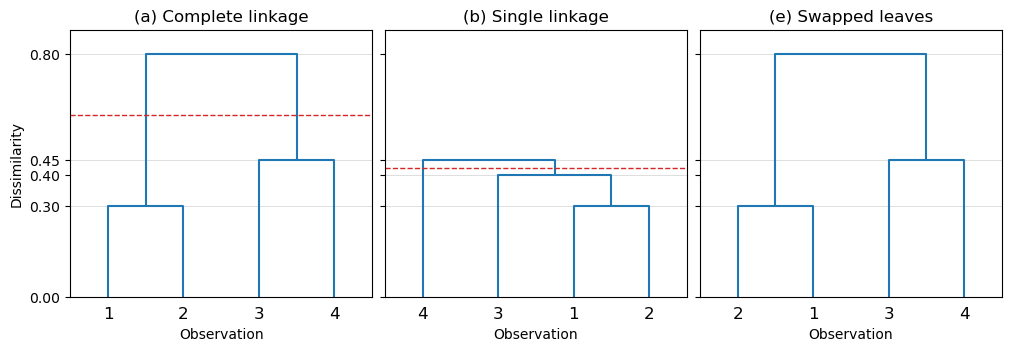

In [28]:
from scipy.cluster.hierarchy import dendrogram, linkage

distances = [0.30, 0.40, 0.70, 0.50, 0.80, 0.45]
complete = linkage(distances, method="complete")
single = linkage(distances, method="single")
swapped = complete.copy()
swapped[0, :2] = swapped[0, :2][::-1]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True, layout="constrained")
plots = [
    (complete, "(a) Complete linkage", [0.30, 0.45, 0.80], 0.60),
    (single, "(b) Single linkage", [0.30, 0.40, 0.45], 0.425),
    (swapped, "(e) Swapped leaves", [0.30, 0.45, 0.80], None),
]
for ax, (tree, title, heights, cut) in zip(axes, plots):
    dendrogram(tree, labels=["1", "2", "3", "4"], ax=ax, color_threshold=0)
    for height in heights:
        ax.axhline(height, color="0.87", linewidth=0.7, zorder=0)
    if cut is not None:
        ax.axhline(cut, color="tab:red", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="Observation", ylim=(0, 0.88),
           yticks=[0, 0.30, 0.40, 0.45, 0.80])
axes[0].set_ylabel("Dissimilarity")
plt.show()
